## Task 1
Linear Regression - Practice data


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt



data=pd.read_excel("Practice_data.xlsx")
df=pd.DataFrame(data)

In [ ]:
df.isnull().sum()
df[df.duplicated()]
df = df.drop_duplicates()

In [ ]:
encoder=LabelEncoder()
df["Gender_encoded"]=encoder.fit_transform(df["Gender"])
df["Department_encoded"]=encoder.fit_transform(df["Department"])
# df["Department_encoded"]=pd.get_dummies(df,columns=['Department'])

In [ ]:
df["Attendance_Pct"]=df["Attendance_Pct"].fillna(df["Attendance_Pct"].median())
df["Study_Hours_Per_Day"]=df["Study_Hours_Per_Day"].fillna(df["Study_Hours_Per_Day"].median())
df["Internal_Marks"]=df["Internal_Marks"].fillna(df["Internal_Marks"].median())
df["Assignments_Completed"]=df["Assignments_Completed"].fillna(df["Assignments_Completed"].median())

In [ ]:
scaler=MinMaxScaler()
df["Attendance_Pct_scaled"]=scaler.fit_transform(df[["Attendance_Pct"]])
df["Study_Hours_Per_Day_scaled"]=scaler.fit_transform(df[["Study_Hours_Per_Day"]])
df["Internal_Marks_scaled"]=scaler.fit_transform(df[["Internal_Marks"]])
df["Assignments_Completed_scaled"]=scaler.fit_transform(df[["Assignments_Completed"]])


In [ ]:
X=df[["Student_ID","Department_encoded","Gender_encoded","Attendance_Pct_scaled","Study_Hours_Per_Day_scaled","Internal_Marks_scaled","Assignments_Completed_scaled"]]
y=df['Final_Score']

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_test)
print(y_pred)

[90.64869457 93.90718572 74.12226774 64.76237734 78.89194772 68.0755277 ]


Text(0, 0.5, 'Predicted Marks')

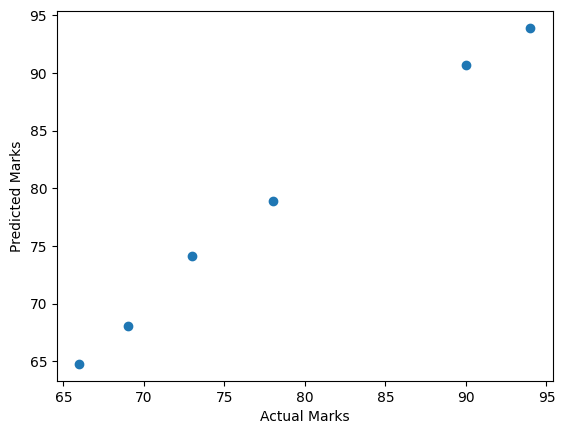

In [ ]:
plt.scatter(y_test,y_pred)
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")

## Task 2
Linear Regression - ML data (sheet2)

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [ ]:
data=pd.read_excel("ML_data.xlsx",sheet_name=1)

In [ ]:
df=pd.DataFrame(data)
df

,Student_ID,Department,Attendance,Study_Hours,Assignment_Score,Internal_Marks,Previous_GPA,Backlogs,Library_Hours,Final_Score,Pass_Fail
0,1001,CSE,92,8.0,88,82,8.6,0,6,87,Pass
1,1002,IT,76,5.0,72,68,7.2,1,3,71,Pass
2,1003,ECE,61,3.5,55,52,6.4,3,1,54,Fail
3,1004,AI&DS,95,9.0,94,91,9.1,0,8,93,Pass
4,1005,BBA,68,4.0,61,58,6.8,2,2,60,Pass


In [ ]:
X=df[["Attendance","Study_Hours","Assignment_Score","Internal_Marks","Previous_GPA","Backlogs","Library_Hours"]]
y=df["Final_Score"]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)
model=LinearRegression()
model.fit(X_train,y_train)
y_pred=model.predict(X_train)
print(y_pred)
print(y_test)

[54. 87. 93.]
1    71
4    60
Name: Final_Score, dtype: int64


In [ ]:
# To find the training error and testing error
y_train_pred=model.predict(X_train)
y_test_pred=model.predict(X_test)
train_error=mean_squared_error(y_train,y_train_pred)
test_error=mean_squared_error(y_test,y_test_pred)
print(train_error)
print(test_error)

3.365806528942984e-28
0.27179862241987784


Logistic Regression - ML data(sheet2)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix, precision_score, recall_score, classification_report

In [ ]:
data=pd.read_excel("ML_data.xlsx",sheet_name=1)

In [ ]:
df=pd.DataFrame(data)
df

,Student_ID,Department,Attendance,Study_Hours,Assignment_Score,Internal_Marks,Previous_GPA,Backlogs,Library_Hours,Final_Score,Pass_Fail
0,1001,CSE,92,8.0,88,82,8.6,0,6,87,Pass
1,1002,IT,76,5.0,72,68,7.2,1,3,71,Pass
2,1003,ECE,61,3.5,55,52,6.4,3,1,54,Fail
3,1004,AI&DS,95,9.0,94,91,9.1,0,8,93,Pass
4,1005,BBA,68,4.0,61,58,6.8,2,2,60,Pass


In [ ]:
X=df[["Attendance","Study_Hours","Assignment_Score","Internal_Marks","Previous_GPA","Backlogs","Library_Hours","Final_Score"]]
y=df["Pass_Fail"]

Precision for Pass
- TP = 1 (actual Pass, predicted Pass)
- FP = 2 (actual Fail, predicted Pass)

Precision pass = 1/1+2 = 0.33

So, recall for Pass = 50%.


Precision for Fail
Now treat Fail as the positive class.
- TP = 0 (actual Fail, predicted Fail)
- FP = 1 (actual Pass, predicted Fail)

Precision fail= 0/0+1=0

So, precision for Fail is 0.00 (0%).

Recall for Pass
Treat Pass as the positive class.
- TP = 1 (actual Pass, predicted Pass)
- FN = 1 (actual Pass, predicted Fail)

Recall_Pass=1/1+1=0.50

So, recall for Pass = 50%.

Recall for Fail
Now treat Fail as the positive class.
- TP = 0 (actual Fail, predicted Fail)
- FN = 2 (actual Fail, predicted Pass)

Recall_Fail=0/0+2=0

So, recall for Fail = 0%.

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42)

model_logistic=LogisticRegression()

model_logistic.fit(X_train,y_train)

y_pred_logistic=model_logistic.predict(X_test)

#metrics
#accuracy
acc=accuracy_score(y_test,y_pred_logistic)

#Confusion matrix
con_mat=confusion_matrix(y_test,y_pred_logistic)

# precision
precision_logistic=precision_score(y_test,y_pred_logistic,pos_label='Pass') # pos_label='fail'.



# pos_label means positive label. It tells Python which class you want to treat as the positive class
# when calculating precision, recall, or F1-score for binary classification

# recall
recall_logistic=recall_score(y_test,y_pred_logistic,pos_label='Pass') # pos_label = 'fail'

# classification report
report=classification_report(y_test,y_pred_logistic)

# Support - in actual data , the count of actual pass and fail data of test data


print(acc)
print(50*"-")
print(y_pred_logistic)
print(50*"-")
print(y_test)
print(50*"-")
print(con_mat)
print(50*"-")
print("Precision")
print(precision_logistic)
print(50*"-")
print("recall")
print(recall_logistic)
print(50*"-")
print(report)

0.5
--------------------------------------------------
['Pass' 'Fail']
--------------------------------------------------
1    Pass
4    Pass
Name: Pass_Fail, dtype: object
--------------------------------------------------
[[0 0]
 [1 1]]
--------------------------------------------------
Precision
1.0
--------------------------------------------------
recall
0.5
--------------------------------------------------
              precision    recall  f1-score   support

        Fail       0.00      0.00      0.00         0
        Pass       1.00      0.50      0.67         2

    accuracy                           0.50         2
   macro avg       0.50      0.25      0.33         2
weighted avg       1.00      0.50      0.67         2



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
